# Where DDD should put $10M: our analysis
**Douglas Gang · DataJam 2026**

**Recommendation:** buy 15 condos in Downtown Eastside, Downtown and Kitsilano for $9.87M, earning about $765K of revenue a year (about 7.7% of the purchase price).

This notebook walks through how we got there. Every number comes from `src/final.py` (also run by `python run.py`).

Data: Inside Airbnb, Vancouver, 15 June 2026 snapshot (scraped 15 June–6 July 2026), CC BY 4.0 · City of Vancouver Open Data, property tax report 2026.

In [1]:
import sys; sys.path.insert(0, "..")
import pandas as pd
from IPython.display import Image
from src import config as C, final
pd.set_option("display.float_format", "{:,.3f}".format)

raw, clean, log = final.load()
d = final.active_whole_homes(clean)
opts = final.options(clean)

## 1. Data and cleaning
We keep listings DDD could actually copy: priced, short-term (minimum stay under 90 nights, the BC + Vancouver rule), active (reviewed in the last 12 months) and whole homes. Suites can't be bought on their own, and Inside Airbnb's two "Strathcona" areas contain only industrial and commercial property in the tax data, so they have no purchase price.

In [2]:
log

,step,rows_before,removed,why
0,has_price,6509,664,price unavailable; bookability cannot be estab...
1,price_in_range,5845,399,outside $30-$2000/night
2,short_term_only,5446,999,min stay >= 90 nights = not a short-term renta...


In [3]:
final.funnel(raw, clean, opts)

,stage,listings
0,Raw listings (15 Jun 2026),6509
1,"Clean: priced $30-$2,000, stay < 90 nights",4447
2,Active whole homes,3137
3,Buyable condos & houses,2487
4,Condos,1307
5,Condos in options with >= 30 listings,1120


## 2. Options and our metric
An **option** is one neighbourhood × property type × bedroom count, e.g. "Downtown Eastside 1-bed condo".

- **Revenue:** median of Inside Airbnb's estimated yearly revenue (`estimated_revenue_l365d`) for that option's listings.
- **Price:** median 2026 assessed value for that neighbourhood and type. The tax data has no bedrooms, so condo prices are scaled: studio 0.70, 1-bed 0.85, 2-bed 1.15, 3+ 1.50 (our assumption).
- **Metric: revenue ÷ price.** The budget is fixed, so we ask how much revenue each dollar buys. Operating costs aren't given in the brief, so we leave them out.

In [4]:
# Trusted options (30+ listings), best first
opts[opts.n >= C.MIN_COMPARABLES].head(12)

,neighbourhood_cleansed,bucket,bedrooms_grp,n,adr_median,nights_booked,occ_median,rev_median,price_cad,gross_yield
2,Downtown Eastside,condo,1,146,368.160,129.000,0.353,"49,140.000","524,875.000",0.094
5,Downtown,condo,1,365,410.000,126.000,0.345,"50,760.000","644,470.000",0.079
7,Downtown,condo,2,288,541.375,120.000,0.329,"63,091.500","871,930.000",0.072
9,Downtown,condo,3+,116,575.080,120.000,0.329,"75,922.500","1,137,300.000",0.067
11,Downtown Eastside,condo,2,79,542.060,90.000,0.247,"43,456.000","710,125.000",0.061
14,Kitsilano,condo,1,31,380.000,114.000,0.312,"47,511.000","840,565.000",0.057
17,Mount Pleasant,condo,1,51,370.890,90.000,0.247,"32,483.000","635,035.000",0.051
21,West End,condo,1,44,416.885,66.000,0.181,"30,147.000","662,690.600",0.045
30,Hastings-Sunrise,house,3+,34,650.885,108.000,0.296,"51,587.000","1,739,050.000",0.030
31,Kensington-Cedar Cottage,house,3+,50,611.315,93.000,0.255,"52,476.000","1,824,000.000",0.029


## 3. Decision 1: condos only
Houses earn similar revenue but cost 2–3× more. Every condo option we trust beats every house option.

In [5]:
trusted = opts[opts.n >= C.MIN_COMPARABLES]
trusted.groupby("bucket")[["rev_median", "price_cad", "gross_yield"]].agg(["min", "max"])

rev_median                price_cad               gross_yield      
              min        max           min           max         min   max
bucket                                                                    
condo  30,147.000 75,922.500   524,875.000 1,137,300.000       0.045 0.094
house  28,062.000 57,549.500 1,739,050.000 3,208,000.000       0.011 0.030

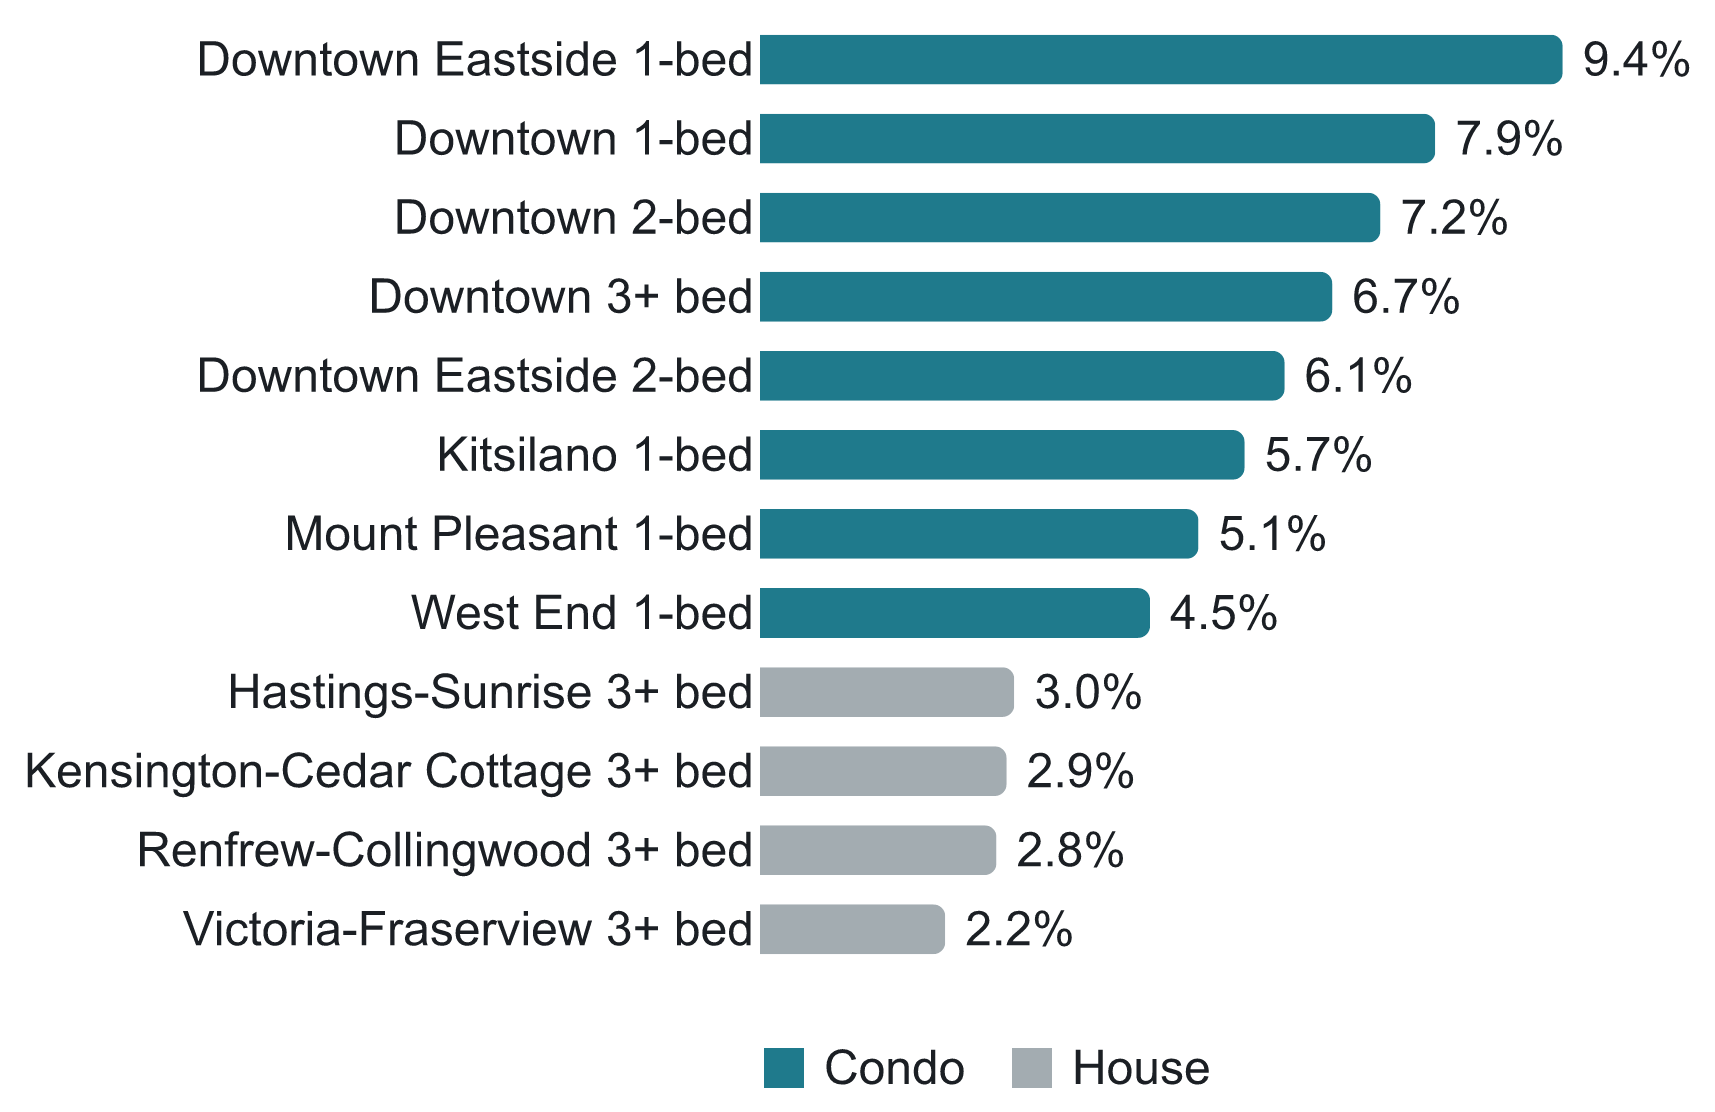

In [6]:
Image("../presentation/charts/condo_vs_house.png", width=650)

## 4. Decision 2: trust only options with 30+ listings
We drew 5,000 random samples from the Downtown 1-bed condos and compared each sample's median revenue with the full median. At 20 listings a median is typically ±17% off; at 30, ±14%. This rule drops West End 2-bed (23 listings) and keeps Kitsilano 1-bed (31).

In [7]:
final.sample_size_test(d)

,listings,typical_error,error_90pct
0,5,0.337,0.720
1,10,0.233,0.533
2,20,0.174,0.409
3,30,0.142,0.339
4,50,0.105,0.259
5,100,0.075,0.162


## 5. The allocation
Rank the trusted condo options by revenue ÷ price and buy from the top, with at most 40% of the $10M in one neighbourhood and at most 10% of an option's listings. In Downtown, 1-bed (7.9%) and 2-bed (7.2%) are within 1 point, so they share the money. Leftover money goes to the next option.

In [8]:
alloc, left = final.allocate(opts)
alloc

,neighbourhood_cleansed,bedrooms_grp,units,listings,price_each,revenue_each,gross_yield,money,revenue,share_of_budget
0,Downtown Eastside,1,7,146,"524,875.000","49,140.000",0.094,"3,674,125.000","343,980.000",0.367
1,Downtown,1,3,365,"644,470.000","50,760.000",0.079,"1,933,410.000","152,280.000",0.193
2,Downtown,2,2,288,"871,930.000","63,091.500",0.072,"1,743,860.000","126,183.000",0.174
3,Kitsilano,1,3,31,"840,565.000","47,511.000",0.057,"2,521,695.000","142,533.000",0.252


In [9]:
print(f"{alloc.units.sum()} units, ${alloc.money.sum():,.0f} spent, ${left:,.0f} left, "
      f"${alloc.revenue.sum():,.0f} revenue/yr, {alloc.revenue.sum() / alloc.money.sum():.1%} revenue ÷ price")

15 units, $9,873,090 spent, $126,910 left, $764,976 revenue/yr, 7.7% revenue ÷ price


## 6. Decision 3: rank by revenue ÷ price, not net yield
Our earlier model ranked by net yield after *assumed* operating costs. It bought fewer, bigger units and less revenue.

In [10]:
final.cost_based_model(opts)

{'units': 13, 'revenue': 691368.0, 'money_spent': 8842975.0}

## 7. Expected 2027 performance
The median listing carried forward to 2027, with a simple range.

In [11]:
rev, money = alloc.revenue.sum(), alloc.money.sum()
pd.DataFrame({"case": ["Revenue −20%", "Expected", "Revenue +10%"], "factor": [0.8, 1.0, 1.1]}).assign(
    revenue=lambda t: rev * t.factor, revenue_over_price=lambda t: rev * t.factor / money)

,case,factor,revenue,revenue_over_price
0,Revenue −20%,0.800,"611,980.800",0.062
1,Expected,1.000,"764,976.000",0.077
2,Revenue +10%,1.100,"841,473.600",0.085


## 8. Demand check
Downtown condos book the most nights. Demand supports our picks, but price decides the return.

In [12]:
final.condo_occupancy(d)

,neighbourhood_cleansed,listings,median_nights,occupancy
1,Downtown,769,126.000,0.345
2,Downtown Eastside,237,108.000,0.296
10,Kitsilano,47,90.000,0.247
21,West End,70,90.000,0.247
12,Mount Pleasant,71,84.000,0.230


## Data checks and limitations
- Scrape dates run from 15 June to 6 July 2026; organisers confirmed newer data is valid.
- Reviews dated after 15 June are ignored when deciding if a listing is active.
- Listings with no bedroom count are treated as 1-bed.
- Revenue and bookings are Inside Airbnb estimates from reviews; nightly prices come from one day; purchase prices are assessed values, not asking prices.

In [13]:
print("Scrape dates:", raw.last_scraped.value_counts().to_dict())
print("Reviews after snapshot:", int((raw.last_review > C.SNAPSHOT_DATE).sum()))
print("Missing bedrooms (clean):", int(clean.bedrooms.isna().sum()))

Scrape dates: {'2026-06-16': 3058, '2026-07-06': 2156, '2026-06-15': 1295}
Reviews after snapshot: 132
Missing bedrooms (clean): 386
